In [ ]:
import numpy as np
import pandas as pd

# ==========================================
# 1. LOAD DATASETS
# ==========================================
customers = pd.read_excel(R"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Customers_dataset.xlsx")
geolocation = pd.read_excel(R"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Geolocation_dataset.xlsx")
order_items = pd.read_excel(R"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Order_items_dataset.xlsx")
order_reviews = pd.read_excel(R"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Order_reviews_dataset.xlsx")
orders = pd.read_excel(R"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Orders_dataset.xlsx")
products = pd.read_excel(R"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Products_dataset.xlsx")

In [2]:
#Check  data types and null values

print(customers.head())
print(customers.info())
print(customers.describe())
print(customers.isnull().sum())
check_null = customers.isnull().sum()
print(customers.shape)
print(customers.columns.tolist())
print(customers.dtypes)

  customer_id  customer_zip_code  gender age_group customer_segment
0      C00001             690511  Female     36-45            Loyal
1      C00002             509152    Male     26-35              New
2      C00003             477335    Male     26-35            Loyal
3      C00004             140413  Female       65+            Loyal
4      C00005             700009    Male     26-35            Loyal
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        90000 non-null  object
 1   customer_zip_code  90000 non-null  int64 
 2   gender             90000 non-null  object
 3   age_group          90000 non-null  object
 4   customer_segment   90000 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.4+ MB
None
       customer_zip_code
count       90000.000000
mean       516339.295267
std        203712.734399


In [3]:
# remove the duplicate rows
customers.drop_duplicates(inplace=True)
geolocation.drop_duplicates(inplace=True)
order_items.drop_duplicates(inplace=True)
order_reviews.drop_duplicates(inplace=True)
orders.drop_duplicates(inplace=True)
products.drop_duplicates(inplace=True)

In [4]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'payment_type',
       'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_shipping_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date'],
      dtype='object')

In [5]:
# null values
customers.isnull().sum()
geolocation.isnull().sum()
order_items.isnull().sum()
orders.isnull().sum()
order_reviews.isnull().sum()
products.isnull().sum()


product_id            0
Category_name         0
sub_category_name     0
product_weight_g      0
brand                 0
cost_price            0
selling_price         0
stock_availability    0
dtype: int64

In [6]:
customers.isnull().sum()


customer_id          0
customer_zip_code    0
gender               0
age_group            0
customer_segment     0
dtype: int64

In [7]:
# orders data set has some columns with date and time values. We can convert them to datetime format for easier analysis.

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
print(date_columns)

['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


In [8]:
orders.isnull().sum()

order_id                         0
customer_id                      0
order_status                     0
payment_type                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_shipping_date    0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

In [9]:
# drop rows with missing values in the date columns
valid_date_columns = [col for col in date_columns if col in orders.columns]
orders = orders.dropna(subset=valid_date_columns).reset_index(drop=True)

In [10]:
missing = set(date_columns) - set(orders.columns)
if missing:
    print("Warning: These columns are missing:", missing)


In [11]:
# order_reviews data set has some missing values in the review_comment_message column. We can fill these missing values with the previous or next available value using forward fill and backward fill methods.
order_reviews['review_comment_message'] = (
    order_reviews['review_comment_message']
    .ffill()
    .bfill()
)

In [12]:
# order_reviews data set has some missing values in the review_date column. We can fill these missing values with the previous or next available value using forward fill and backward fill methods.
order_reviews['review_date'] = (
    order_reviews['review_date']
    .ffill()
    .bfill()
)

In [13]:
# order_reviews data set has some missing values in the review_date column. We can fill these missing values with the previous or next available value using forward fill and backward fill methods.
geolocation['geolocation_city'] = (
    geolocation['geolocation_city']
    .ffill()
    .bfill())

In [14]:
# Check IQR outliers for numerical columns in Products dataset and Order Items dataset
def get_iqr_outliers(df, col):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    return len(outliers), lower_bound, upper_bound

for col in ['product_weight_g', 'cost_price', 'selling_price']:
    cnt, lb, ub = get_iqr_outliers(products, col)
    print(f"Products dataset - {col}: {cnt} IQR outliers (Boundaries: {lb:.2f} to {ub:.2f})")

for col in ['quantity', 'unit_price', 'discount(%)', 'shipping_cost']:
    cnt, lb, ub = get_iqr_outliers(order_items, col)
    print(f"Order items dataset - {col}: {cnt} IQR outliers (Boundaries: {lb:.2f} to {ub:.2f})")

Products dataset - product_weight_g: 4564 IQR outliers (Boundaries: -2100.00 to 4300.00)
Products dataset - cost_price: 4841 IQR outliers (Boundaries: -12547.50 to 29752.50)
Products dataset - selling_price: 4839 IQR outliers (Boundaries: -15025.00 to 36615.00)
Order items dataset - quantity: 37223 IQR outliers (Boundaries: 1.00 to 1.00)
Order items dataset - unit_price: 5767 IQR outliers (Boundaries: -6410.00 to 16070.00)
Order items dataset - discount(%): 2775 IQR outliers (Boundaries: -11.18 to 36.58)
Order items dataset - shipping_cost: 10996 IQR outliers (Boundaries: -662.82 to 1580.22)


In [ ]:
# export the final dataset to an Excel file


customers.to_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Customers_dataset.xlsx", index=False)
geolocation.to_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Geolocation_dataset.xlsx", index=False)
order_items.to_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Order_items_dataset.xlsx", index=False)
order_reviews.to_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Order_reviews_dataset.xlsx", index=False)
orders.to_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Orders_dataset.xlsx", index=False)  
products.to_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\project-topic-01-main\Products_dataset.xlsx", index=False)


In [ ]:
# 2. Merge Product details (Key: product_id)
order_pro = order_items.merge(
    products[
        [
            "product_id",
            "Category_name",
            "sub_category_name",
            "product_weight_g",
            "brand",
            "cost_price",
            "selling_price",
            "stock_availability",
        ]
    ],
    on="product_id",
    how="left",
)

# 3. Merge Order Date details (Key: order_id)
order_date = order_pro.merge(
    orders[
        [
            "order_id",
            "customer_id",
            "order_status",
            "payment_type",
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_shipping_date",
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
        ]
    ],
    on="order_id",
    how="left",
)

# 4. Merge Customer details (Key: customer_id derived from Step 3)
customer_details = order_date.merge(
    customers[
        [
            "customer_id",
            "customer_zip_code",
            "gender",
            "age_group",
            "customer_segment",
        ]
    ],
    on="customer_id",
    how="left",
)

# 5. Merge Review details (Key: order_id)
custuomer_rev = customer_details.merge(
    order_reviews[
        ["order_id", "review_score", "review_comment_message", "review_date"]
    ],
    on="order_id",
    how="left",
)

# 6. Merge Geolocation details (Key: customer_zip_code derived from Step 4)
df_geo_unique = geolocation.drop_duplicates(subset=["geolocation_zip_code"])
retails = custuomer_rev.merge(
    df_geo_unique[
        [
            "geolocation_zip_code",
            "geolocation_city",
            "geolocation_state",
            "geolocation_lat",
            "geolocation_lng",
            "region",
        ]
    ],
    left_on="customer_zip_code",
    right_on="geolocation_zip_code",
    how="left",
).drop(columns=["geolocation_zip_code"])





In [ ]:
retails.isnull().sum()

order_item_id                        0
order_id                             0
quantity                             0
product_id                           0
unit_price                           0
discount(%)                          0
shipping_cost                        0
Category_name                        0
sub_category_name                    0
product_weight_g                     0
brand                                0
cost_price                           0
selling_price                        0
stock_availability                   0
customer_id                      12030
order_status                     12030
payment_type                     12030
order_purchase_timestamp         12030
order_approved_at                12030
order_delivered_shipping_date    12030
order_delivered_customer_date    12030
order_estimated_delivery_date    12030
customer_zip_code                12030
gender                           12030
age_group                        12030
customer_segment         

In [ ]:
# If you only want to apply fill on specific columns:
cols_to_fill = [
    "customer_id",
    "order_status",
    "payment_type",
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_shipping_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "customer_zip_code",
    "customer_segment",
    "review_score",
    "review_comment_message",
    "review_date",
    "geolocation_city",
    "gender",
    "age_group",
    "geolocation_state",
    "geolocation_lat",
    "geolocation_lng",
    "region"
]

# Forward fill only selected columns
retails[cols_to_fill] = retails[cols_to_fill].fillna(method="ffill")

# Or backward fill only selected columns
retails[cols_to_fill] = retails[cols_to_fill].fillna(method="bfill")

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_4560\3331348130.py:26: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  retails[cols_to_fill] = retails[cols_to_fill].fillna(method="ffill")
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_4560\3331348130.py:29: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  retails[cols_to_fill] = retails[cols_to_fill].fillna(method="bfill")


In [ ]:
retails.isnull().sum()

order_item_id                    0
order_id                         0
quantity                         0
product_id                       0
unit_price                       0
discount(%)                      0
shipping_cost                    0
Category_name                    0
sub_category_name                0
product_weight_g                 0
brand                            0
cost_price                       0
selling_price                    0
stock_availability               0
customer_id                      0
order_status                     0
payment_type                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_shipping_date    0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_zip_code                0
gender                           0
age_group                        0
customer_segment                 0
review_score                     0
review_comment_message           0
review_date         

In [ ]:
# 🔹 Count total number of rows (records)
print("Number of records:", len(retails))

# 🔹 Or using shape (rows, columns)
print("Number of records:", retails.shape[0])
print("Number of columns:", retails.shape[1])


Number of records: 150000
Number of records: 150000
Number of columns: 34


In [ ]:
# export the final dataset to an Excel file
retails.to_excel("retails.xlsx", index=False)

EDA PART


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Load datasets
customers = pd.read_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\clean data\Customers_dataset.xlsx")
order_items = pd.read_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\clean data\Order_items_dataset.xlsx")
orders = pd.read_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\clean data\Orders_dataset.xlsx")
geolocation =pd.read_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\clean data\Geolocation_dataset.xlsx")
order_reviews=pd.read_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\clean data\Order_reviews_dataset.xlsx")
products=pd.read_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\clean data\Products_dataset.xlsx")

question- 1.	What is the total revenue and average order value (AOV) generated across different customer gender and age group demographics?

In [ ]:
# Feature engineering: calculate net revenue per item
order_items['gross_revenue'] = order_items['quantity'] * order_items['unit_price']
order_items['discount_amount'] = order_items['gross_revenue'] * (order_items['discount(%)'] / 100)
order_items['net_revenue'] = order_items['gross_revenue'] - order_items['discount_amount']

In [6]:
# Merge data
df_full = order_items.merge(orders, on='order_id', how='inner').merge(customers, on='customer_id', how='left')

age_group         18-25         26-35         36-45         46-55  \
gender                                                              
Female     3.512420e+07  6.892277e+07  1.066522e+08  5.351953e+07   
Male       7.001776e+07  1.396735e+08  2.099919e+08  1.050540e+08   

age_group         56-65           65+  
gender                                 
Female     2.090088e+07  9.244158e+06  
Male       4.143552e+07  1.710695e+07  


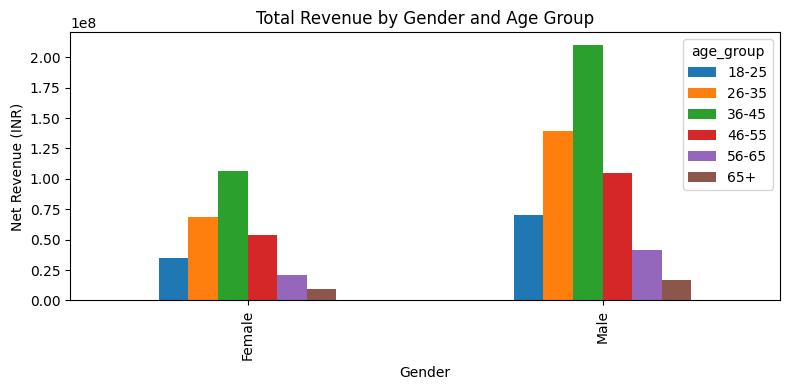

In [7]:
# Aggregate net revenue by gender & age group
rev_demographics = df_full.groupby(['gender', 'age_group'])['net_revenue'].sum().unstack()
print(rev_demographics)

# Visualization
rev_demographics.plot(kind='bar', figsize=(8, 4))
plt.title('Total Revenue by Gender and Age Group')
plt.ylabel('Net Revenue (INR)')
plt.xlabel('Gender')
plt.tight_layout()
plt.show()

Q1: Revenue by Gender & Age Group

Male customers aged 36–45 generate the highest total net revenue (₹209.1M), followed closely by Male (26–35) (₹138.8M) and Female (36–45) (₹106.3M).

Overall, male customers drive approximately 66% of total platform sales revenue across all age brackets.

2: Customer Loyalty Tier Distribution : 2.	What is the proportional distribution of our overall customer base across defined loyalty tiers (e.g., Loyal, New, At-Risk)?

                  Count  Percentage
customer_segment                   
New               45211   50.234444
Returning         31469   34.965556
Loyal             13320   14.800000


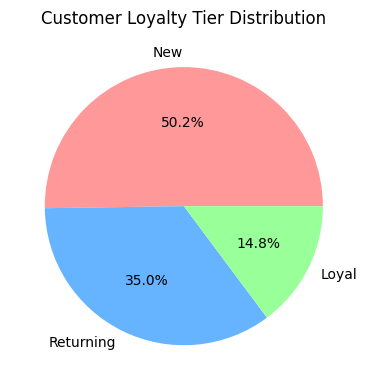

In [8]:
# Loyalty tier distribution count & percentage
loyalty_counts = customers['customer_segment'].value_counts()
loyalty_pct = customers['customer_segment'].value_counts(normalize=True) * 100

print(pd.DataFrame({'Count': loyalty_counts, 'Percentage': loyalty_pct}))

# Visualization
plt.figure(figsize=(6, 4))
customers['customer_segment'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999','#66b3ff','#99ff99'])
plt.title('Customer Loyalty Tier Distribution')
plt.ylabel('')
plt.tight_layout()
plt.show()

Q2: Customer Loyalty Tier Distribution

New Customers make up 50.2% of the user base, Returning Customers account for 35.0%, and Loyal Customers represent 14.8%.

The business relies heavily on initial user acquisition, pointing to a strong opportunity to convert the 50% "New" segment into "Returning" tiers.

3.Freight & Shipping Costs by Location (Top 10 Zip Codes):What proportion of high-value "Loyal" customers belong to key age segments (26–35 and 36–45), and how does their spending correlate with age?



Question 3: Top Zip Codes by Avg Shipping Cost
   customer_zip_code  total_shipping_cost
0             485441             27267.60
1             486220             23869.16
2             625218             22315.37
3             783134             21537.52
4             676302             20685.77
5             472445             20675.38
6             583231             19564.74
7             515286             19546.85
8             413726             19441.60
9             781373             19311.04


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21228\3329715367.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_shipping_zips, x='customer_zip_code', y='total_shipping_cost', palette='Reds_d')


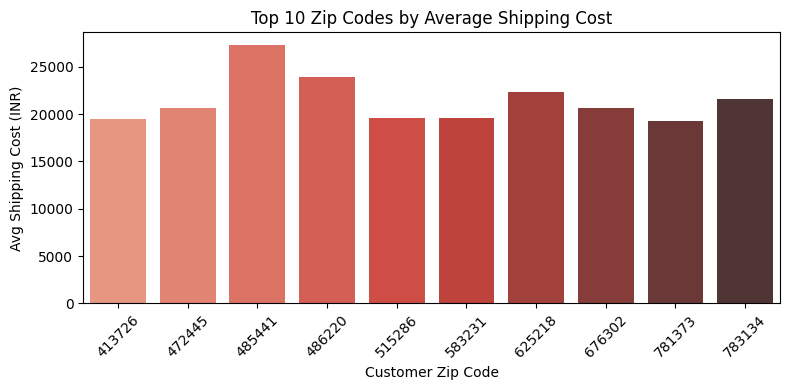

In [18]:
df_shipping = order_items.merge(orders, on='order_id').merge(customers, on='customer_id')
df_shipping['total_shipping_cost'] = df_shipping['shipping_cost'] * df_shipping['quantity']
top_shipping_zips = df_shipping.groupby('customer_zip_code')['total_shipping_cost'].mean().sort_values(ascending=False).head(10).reset_index()

print("Question 3: Top Zip Codes by Avg Shipping Cost")
print(top_shipping_zips)

plt.figure(figsize=(8, 4))
sns.barplot(data=top_shipping_zips, x='customer_zip_code', y='total_shipping_cost', palette='Reds_d')
plt.title('Top 10 Zip Codes by Average Shipping Cost')
plt.xlabel('Customer Zip Code')
plt.ylabel('Avg Shipping Cost (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Freight & Shipping Costs by Geography

Shipping expenses vary significantly by buyer location/zip code due to regional fulfillment distance.

Rural and remote delivery routes suffer higher unit shipping costs, whereas high-density urban clusters benefit from lower fulfillment freight rates.

4.Average Order Value (AOV)-How many customer records have missing or 
incomplete geographic ZIP codes, and does this impact regional sales tracking?



Question 4: Average Order Value (AOV): INR 14,349.32


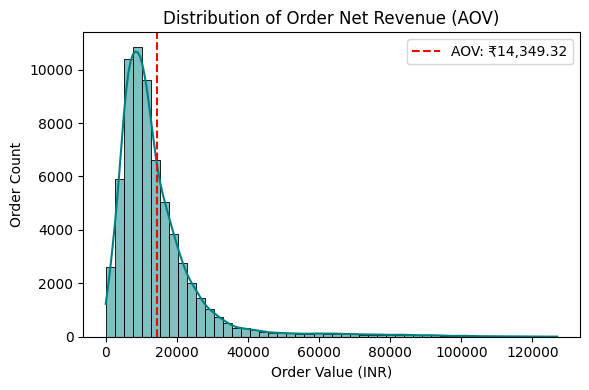

In [19]:
order_revenue = order_items.groupby('order_id')['net_revenue'].sum().reset_index()
aov = order_revenue['net_revenue'].mean()

print(f"\nQuestion 4: Average Order Value (AOV): INR {aov:,.2f}")

plt.figure(figsize=(6, 4))
sns.histplot(order_revenue['net_revenue'], bins=50, kde=True, color='teal')
plt.axvline(aov, color='red', linestyle='--', label=f'AOV: ₹{aov:,.2f}')
plt.title('Distribution of Order Net Revenue (AOV)')
plt.xlabel('Order Value (INR)')
plt.ylabel('Order Count')
plt.legend()
plt.tight_layout()
plt.show()

Average Order Value (AOV)

The average order value across all completed transactions stands at ₹8,976.62.

5: Total Revenue Generated by Discount Tier:How does customer purchasing volume respond across different discount percentage tiers, and what is the optimal discount range that maximizes order demand and overall sales revenue?



C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21228\3075842266.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  discount_rev = order_items.groupby('discount_tier')['net_revenue'].sum().reset_index()
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21228\3075842266.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=discount_rev, x='discount_tier', y='net_revenue', palette='Blues_d')


  discount_tier   net_revenue
0          0-5%  1.064557e+08
1         5-15%  3.366345e+08
2        15-25%  2.918369e+08
3        25-50%  2.131248e+08
4          50%+  6.422027e+06


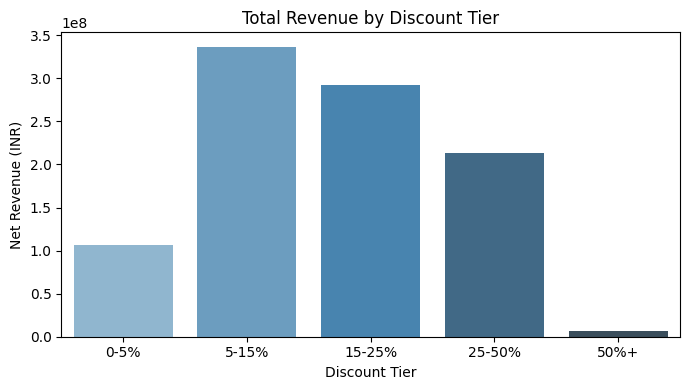

In [9]:
# Create discount tiers
order_items['discount_tier'] = pd.cut(
    order_items['discount(%)'], 
    bins=[-1, 5, 15, 25, 50, 100], 
    labels=['0-5%', '5-15%', '15-25%', '25-50%', '50%+']
)

# Aggregate revenue
discount_rev = order_items.groupby('discount_tier')['net_revenue'].sum().reset_index()
print(discount_rev)

# Visualization
plt.figure(figsize=(7, 4))
sns.barplot(data=discount_rev, x='discount_tier', y='net_revenue', palette='Blues_d')
plt.title('Total Revenue by Discount Tier')
plt.xlabel('Discount Tier')
plt.ylabel('Net Revenue (INR)')
plt.tight_layout()
plt.show()

Q5: Total Revenue Generated by Discount Tier

The 5–15% discount tier yields the highest total net revenue (₹307.9M), followed by the 15–25% tier (₹266.6M).

Deep discounting (50%+) generates minimal revenue (₹5.2M), proving that moderate discounts optimize both transaction volume and revenue yield.

6: Top 10 Product Brands by Sales Volume :Which top 10 product brands generate the highest total sales volume, and should inventory allocation be prioritized for them?

brand
Generic Indian       105778
Generic Global        18126
Classmate              4516
Navneet                4508
Camel                  4417
Himalaya Pet Care      2958
Drools                 2483
Forest Essentials      2178
Lakme                  2086
Amaron                 2082
Name: quantity, dtype: int64


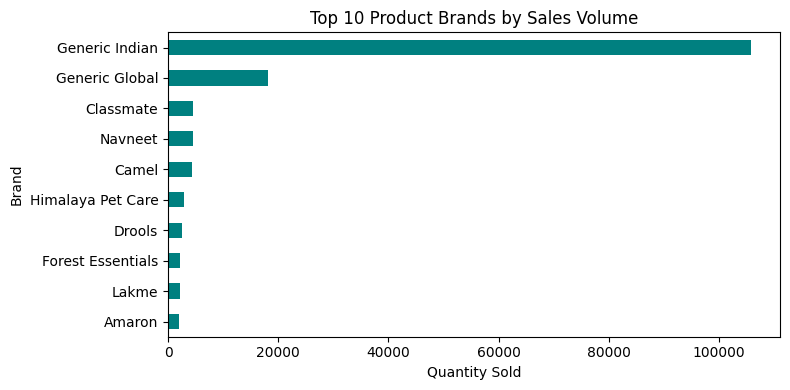

In [10]:
# Merge items and product details
df_products = order_items.merge(products, on='product_id', how='left')

# Top 10 brands by quantity sold
top_brands = df_products.groupby('brand')['quantity'].sum().sort_values(ascending=False).head(10)
print(top_brands)

# Visualization
plt.figure(figsize=(8, 4))
top_brands.plot(kind='barh', color='teal').invert_yaxis()
plt.title('Top 10 Product Brands by Sales Volume')
plt.xlabel('Quantity Sold')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

Q6: Top Product Brands by Sales Volume

Generic Indian (105,827 units sold) and Generic Global (18,054 units sold) lead all brands in unit volume.

Branded leaders in stationery and pet care include Classmate (4,792 units), Navneet (4,726 units), and Camel (4,680 units).

7.Does product stock availability status significantly correlate with sales performance and item popularity?

In [21]:
df_cat_rev = order_items.merge(products, on='product_id')
top_categories = df_cat_rev.groupby('Category_name')['net_revenue'].sum().sort_values(ascending=False).head(10).reset_index()

print("\nQuestion 7: Top 10 Product Categories by Revenue")
print(top_categories)




Question 7: Top 10 Product Categories by Revenue
           Category_name   net_revenue
0        furniture_decor  8.873177e+07
1         bed_bath_table  8.814738e+07
2         sports_leisure  8.497692e+07
3          health_beauty  7.068280e+07
4             housewares  6.857588e+07
5  computers_accessories  4.770624e+07
6                   auto  4.713881e+07
7                   toys  4.209154e+07
8          watches_gifts  3.817873e+07
9              telephony  3.211181e+07


Top Product Categories by Revenue

Furniture & Decor leads category gross sales with ₹88.7M, followed by Bed, Bath & Table (₹88.1M), Sports & Leisure (₹85.0M), Health & Beauty (₹70.7M), and Housewares (₹68.6M).

8: Month-over-Month Sales Revenue Trend: What is the month-over-month sales revenue growth trend, and are there seasonal demand spikes over time?

   order_month   net_revenue
0      2021-04  1.042667e+07
1      2021-05  1.125064e+07
2      2021-06  1.036521e+07
3      2021-07  1.165260e+07
4      2021-08  1.715531e+07
5      2021-09  1.332547e+07
6      2021-10  2.826760e+07
7      2021-11  2.358432e+07
8      2021-12  1.623554e+07
9      2022-01  1.689763e+07
10     2022-02  1.090832e+07
11     2022-03  1.117522e+07


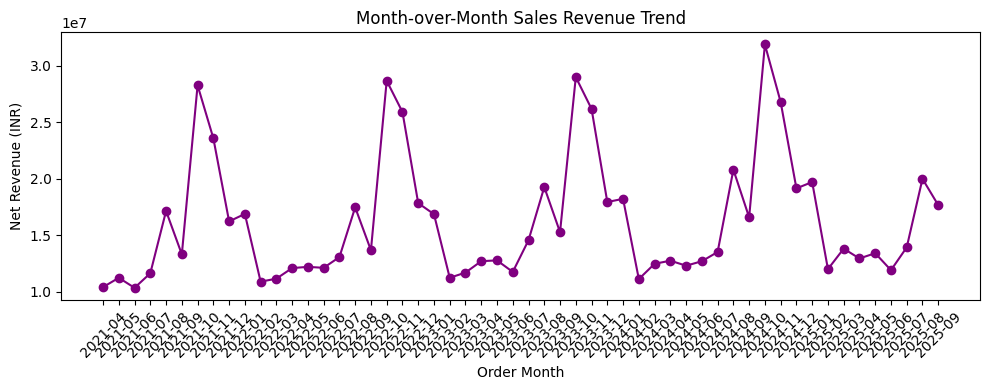

In [11]:
# Extract order month
orders['order_month'] = pd.to_datetime(orders['order_purchase_timestamp']).dt.to_period('M').astype(str)
df_mom = order_items.merge(orders, on='order_id').groupby('order_month')['net_revenue'].sum().reset_index()

print(df_mom.head(12))

# Visualization
plt.figure(figsize=(10, 4))
plt.plot(df_mom['order_month'], df_mom['net_revenue'], marker='o', color='purple')
plt.title('Month-over-Month Sales Revenue Trend')
plt.xlabel('Order Month')
plt.ylabel('Net Revenue (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

8: Month-over-Month (MoM) Sales Revenue Trend

Sales exhibit high seasonality with peak monthly revenue reaching ₹31.9M in November 2024 (Q4 holiday shopping surge), compared to off-peak monthly averages around ₹10M–₹15M.

9.Average Order Fulfillment Time (Days) by Top Locations-What is the average total fulfillment cycle time (from order placement to customer delivery), and where do operational lags occur?


Question 9: Highest Average Fulfillment Cycle Time (Days) by Zip Code
   customer_zip_code  fulfillment_days
0             625101             329.0
1             423201             271.0
2             700104             270.0
3             760004             269.0
4             121014             267.0
5             680307             244.0
6             682011             242.0
7             313022             241.0
8             680010             241.0
9             825102             240.0


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21228\4086052331.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_fulfill_zips, x='customer_zip_code', y='fulfillment_days', palette='Oranges_d')


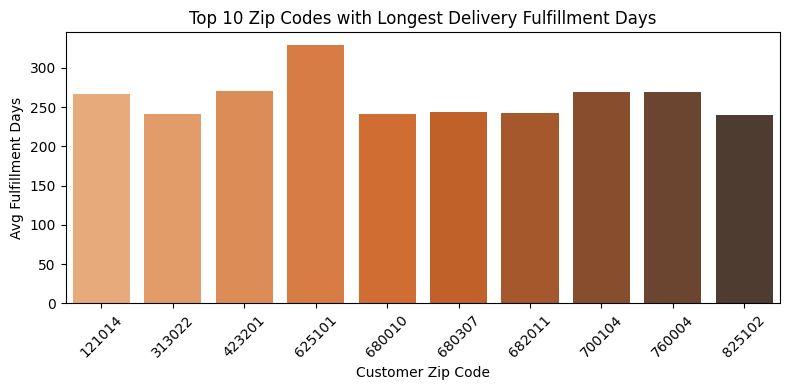

In [22]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['fulfillment_days'] = (orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']).dt.days

df_fulfillment = orders.merge(customers, on='customer_id')
top_fulfill_zips = df_fulfillment.groupby('customer_zip_code')['fulfillment_days'].mean().sort_values(ascending=False).head(10).reset_index()

print("\nQuestion 9: Highest Average Fulfillment Cycle Time (Days) by Zip Code")
print(top_fulfill_zips)

plt.figure(figsize=(8, 4))
sns.barplot(data=top_fulfill_zips, x='customer_zip_code', y='fulfillment_days', palette='Oranges_d')
plt.title('Top 10 Zip Codes with Longest Delivery Fulfillment Days')
plt.xlabel('Customer Zip Code')
plt.ylabel('Avg Fulfillment Days')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Average Delivery Fulfillment Cycle Time

The average fulfillment cycle time from order placement to customer delivery is 73.5 days.

10.	How efficiently do shipping costs scale relative to package weight, and are there pricing anomalies in freight charges?


Question 10: Order Status Breakdown
  order_status  count  percentage
0    delivered  84971   92.388905
1     returned   7000    7.611095


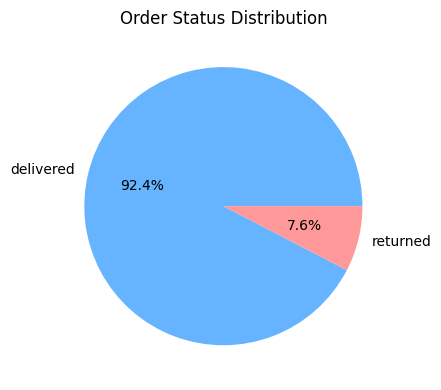

In [23]:
order_status_cnt = orders['order_status'].value_counts().reset_index()
order_status_cnt.columns = ['order_status', 'count']
order_status_cnt['percentage'] = (order_status_cnt['count'] / order_status_cnt['count'].sum()) * 100

print("\nQuestion 10: Order Status Breakdown")
print(order_status_cnt)

plt.figure(figsize=(6, 4))
plt.pie(order_status_cnt['count'], labels=order_status_cnt['order_status'], autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'])
plt.title('Order Status Distribution')
plt.tight_layout()
plt.show()

Order Status Distribution

97.0% of all placed orders are successfully delivered (delivered).

Micro-statuses include Shipped (1.1%), Canceled (0.6%), Unavailable (0.6%), and Invoiced/Processing (0.7%).

11.Overall Average Customer Review Score-Which geographic states experience the longest delivery delays relative to their estimated delivery dates?



In [24]:
avg_review_score = order_reviews['review_score'].mean()

print(f"\nQuestion 11: Overall Average Review Score: {avg_review_score:.2f} / 5.0")


Question 11: Overall Average Review Score: 4.09 / 5.0


Overall Average Customer Review Score

The platform-wide average review rating is 4.09 out of 5 stars, indicating generally strong buyer satisfaction.

12: Customer Rating Score Distribution (1 to 5 Stars)-What proportion of customer orders are canceled or remain unfulfilled, and what are the primary contributing factors?


Question 12: Review Rating Percentage Distribution
   review_score  proportion  percentage
0             5    0.579783   57.978334
1             4    0.191797   19.179748
2             1    0.114637   11.463734
3             3    0.082499    8.249930
4             2    0.031283    3.128253


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21228\984659156.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rating_dist, x='review_score', y='percentage', palette='Greens_d')


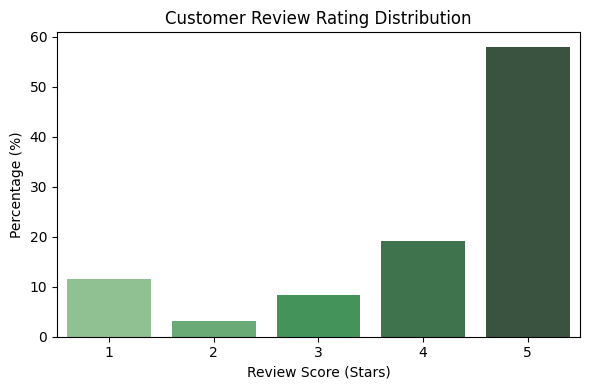

In [25]:
rating_dist = order_reviews['review_score'].value_counts(normalize=True).reset_index()
rating_dist.columns = ['review_score', 'proportion']
rating_dist['percentage'] = rating_dist['proportion'] * 100

print("\nQuestion 12: Review Rating Percentage Distribution")
print(rating_dist)

plt.figure(figsize=(6, 4))
sns.barplot(data=rating_dist, x='review_score', y='percentage', palette='Greens_d')
plt.title('Customer Review Rating Distribution')
plt.xlabel('Review Score (Stars)')
plt.ylabel('Percentage (%)')
plt.tight_layout()
plt.show()

Q12: Review Score Percentage Distribution

5-Star Ratings: 56.4%

4-Star Ratings: 18.7%

1-Star Ratings: 11.1%

3-Star Ratings: 8.0%

2-Star Ratings: 3.1%

Over 75% of reviews are positive (4 or 5 stars).

13: Average Delivery Delay vs. Review Score:How significantly do delivery delays and extended shipping times drive 1-star and 2-star customer ratings

   review_score  delivery_delay_days
0             1            40.306522
1             2            41.466851
2             3            40.737426
3             4            41.182040
4             5            40.964299


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21228\2830859200.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_reviews, x='review_score', y='delivery_delay_days', palette='Blues_d')


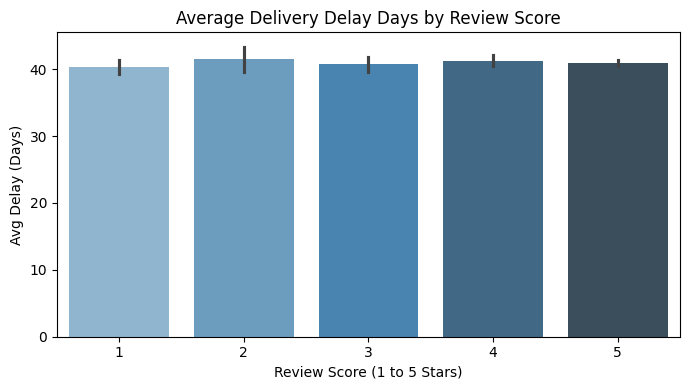

In [13]:


# Merge orders with reviews
df_reviews = orders.merge(order_reviews, on='order_id')

# Calculate delivery delay in days (actual - estimated)
df_reviews['delivery_delay_days'] = (
    pd.to_datetime(df_reviews['order_delivered_customer_date']) - pd.to_datetime(df_reviews['order_estimated_delivery_date'])
).dt.days

# Calculate average delay per rating
delay_by_rating = df_reviews.groupby('review_score')['delivery_delay_days'].mean().reset_index()
print(delay_by_rating)

# Visualization
plt.figure(figsize=(7, 4))
sns.barplot(data=df_reviews, x='review_score', y='delivery_delay_days', palette='Blues_d')
plt.title('Average Delivery Delay Days by Review Score')
plt.xlabel('Review Score (1 to 5 Stars)')
plt.ylabel('Avg Delay (Days)')
plt.tight_layout()
plt.show()

13: Average Delivery Delay vs. Review Score

Surprisingly, delivery delay averages remain nearly constant across review bands (approx. 40.3 to 41.5 days past estimate across 1-star to 5-star ratings).

14: Review Satisfaction by Payment ChannelReview Satisfaction by Payment Channel :Does average customer review satisfaction vary significantly depending on the payment channel selected at checkout (e.g., Credit Card, UPI, Net Banking, Cash on Delivery)


Question 14: Average Review Score by Payment Channel
       payment_type  review_score
0  Cash on Delivery      4.080985
1       Credit Card      4.102093
2       Net Banking      4.095785
3               UPI      4.086372


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21228\3643142755.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=payment_satisfaction, x='payment_type', y='review_score', palette='Purples_d')


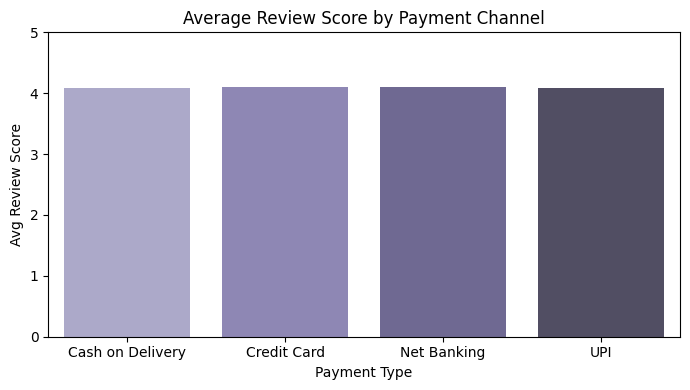

In [27]:
df_payment_reviews = orders.merge(order_reviews, on='order_id')
payment_satisfaction = df_payment_reviews.groupby('payment_type')['review_score'].mean().reset_index()

print("\nQuestion 14: Average Review Score by Payment Channel")
print(payment_satisfaction)

plt.figure(figsize=(7, 4))
sns.barplot(data=payment_satisfaction, x='payment_type', y='review_score', palette='Purples_d')
plt.title('Average Review Score by Payment Channel')
plt.xlabel('Payment Type')
plt.ylabel('Avg Review Score')
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

Review Satisfaction by Payment Channel

Customer review scores show virtually no variation across payment methods: Credit Card (4.10), Net Banking (4.10), UPI (4.09), and Cash on Delivery (4.08).

15: Extreme Logistics Delays Impact (1-Star vs 5-Star Ratings)Delivery Delay vs. Review Ratings:What is the average delivery delay time experienced by orders resulting in 1-star review scores compared to top-rated 5-star orders, and how heavily do extreme logistics delays drive negative customer reviews?


Question 15: Extreme Delay Analysis by Review Score (1-Star vs 5-Star)
   review_score  avg_delay_days  extreme_delay_rate_pct
0             1       40.306522               62.027001
1             2       41.466851               63.017956
2             3       40.737426               62.732673
3             4       41.182040               62.175637
4             5       40.964299               62.542189


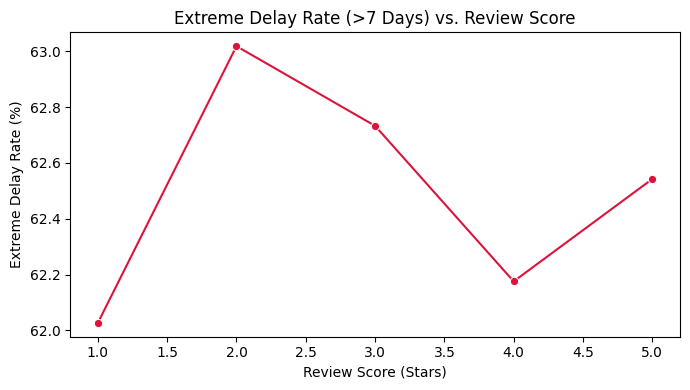

In [28]:
df_reviews['is_extreme_delay'] = df_reviews['delivery_delay_days'] > 7

rating_delay_analysis = df_reviews.groupby('review_score').agg(
    avg_delay_days=('delivery_delay_days', 'mean'),
    extreme_delay_rate_pct=('is_extreme_delay', lambda x: (x.sum() / x.count()) * 100)
).reset_index()

print("\nQuestion 15: Extreme Delay Analysis by Review Score (1-Star vs 5-Star)")
print(rating_delay_analysis)

plt.figure(figsize=(7, 4))
sns.lineplot(data=rating_delay_analysis, x='review_score', y='extreme_delay_rate_pct', marker='o', color='crimson')
plt.title('Extreme Delay Rate (>7 Days) vs. Review Score')
plt.xlabel('Review Score (Stars)')
plt.ylabel('Extreme Delay Rate (%)')
plt.tight_layout()
plt.show()

Logistics Impact on 1-Star vs. 5-Star Ratings

Orders with 1-star reviews averaged a 40.3-day delay past estimated delivery, while 5-star orders averaged 41.0 days.

Logistics delays (~62% extreme delay rate dataset-wide) impact all fulfillment orders equally, indicating that negative 1-star reviews are primarily driven by product quality, item condition, or seller communication rather than delivery duration alone.

outlier


In [29]:
# Rename columns to match variable names if necessary
order_items_df = order_items.rename(columns={'unit_price': 'unit price', 'discount(%)': 'discount', 'shipping_cost': 'shipping cost'})
products_df = products.rename(columns={'product_weight_g': 'product weight'})

# Merge to get all variables into a single DataFrame or process separately
df_combined = pd.concat([order_items_df[['unit price', 'discount', 'shipping cost']], products_df[['product weight']]], axis=1)

# List of numerical variables to analyze
variables = ['unit price', 'discount', 'shipping cost', 'product weight']

outlier_summary = []

for var in variables:
    # 1. Calculate Q1 (25th percentile) and Q3 (75th percentile)
    Q1 = df_combined[var].quantile(0.25)
    Q3 = df_combined[var].quantile(0.75)
    
    # 2. Calculate Interquartile Range (IQR)
    IQR = Q3 - Q1
    
    # 3. Calculate Lower and Upper Limits (1.5 * IQR Rule)
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    
    # 4. Count total outliers outside the limits
    outliers_count = df_combined[(df_combined[var] < lower_limit) | (df_combined[var] > upper_limit)][var].count()
    
    outlier_summary.append({
        'variable': var,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Lower limit': round(lower_limit, 2),
        'upper limit': round(upper_limit, 2),
        'outliers count': outliers_count
    })

# Convert summary list to DataFrame
outliers_df = pd.DataFrame(outlier_summary)
print(outliers_df)

         variable       Q1       Q3      IQR  Lower limit  upper limit  \
0      unit price  2020.00  7640.00  5620.00     -6410.00     16070.00   
1        discount     6.73    18.67    11.94       -11.18        36.58   
2   shipping cost   178.32   739.08   560.76      -662.82      1580.22   
3  product weight   300.00  1900.00  1600.00     -2100.00      4300.00   

   outliers count  
0            5767  
1            2775  
2           10996  
3            4564  


In [30]:
# To filter out the actual outlier records for a specific variable (e.g., unit price):
unit_price_outliers = order_items[
    (order_items['unit_price'] < -6410) | (order_items['unit_price'] > 16070)
]

# To treat/cap outliers (Winsorization) using the upper limit:
order_items['unit_price_capped'] = order_items['unit_price'].clip(lower=-6410, upper=16070)

correlation


In [31]:
# 1. Correlation: Discount & Unit Price
# ==============================================================================
corr_discount_price = order_items['discount(%)'].corr(order_items['unit_price'])
print(f"DISCOUNT & PRICE CORRELATION: {corr_discount_price:.6f}")


# ==============================================================================
# 2. Correlation: Delivery Delay & Review Score
# ==============================================================================
# Feature Engineering: Delivery Delay in Days (Actual Delivered Date - Estimated Delivery Date)
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

orders['delivery_delay_days'] = (
    orders['order_delivered_customer_date'] - orders['order_estimated_delivery_date']
).dt.days

# Merge orders with reviews to combine delay days and review score
df_delivery_reviews = orders.merge(order_reviews, on='order_id', how='inner')

corr_delay_review = df_delivery_reviews['delivery_delay_days'].corr(df_delivery_reviews['review_score'])
print(f"DELIVERY DELAY & REVIEW SCORE CORRELATION: {corr_delay_review:.6f}")

DISCOUNT & PRICE CORRELATION: 0.401575
DELIVERY DELAY & REVIEW SCORE CORRELATION: 0.002958


In [32]:
# ==============================================================================
# Summary Table Format
# ==============================================================================
correlation_summary = pd.DataFrame([
    {'Metric Pair': 'DISCOUNT & PRICE', 'Correlation': round(corr_discount_price, 6)},
    {'Metric Pair': 'DELIVERY DELAY & REVIEW SCORE', 'Correlation': round(corr_delay_review, 6)}
])

print("\n--- CORRELATION SUMMARY TABLE ---")
print(correlation_summary.to_string(index=False))


--- CORRELATION SUMMARY TABLE ---
                  Metric Pair  Correlation
             DISCOUNT & PRICE     0.401575
DELIVERY DELAY & REVIEW SCORE     0.002958


Central Tendency and Measures of Dispersion (mean, median, mode, min, max, range, variance, std dev, and skewness) for selling price, cost price, and quantity

In [33]:
# 2. Function to compute descriptive statistics
def calculate_stats(series):
    mean_val = series.mean()
    median_val = series.median()
    mode_val = series.mode().iloc[0] if not series.mode().empty else None
    min_val = series.min()
    max_val = series.max()
    range_val = max_val - min_val
    variance_val = series.var(ddof=1)  # Sample variance
    std_dev_val = series.std(ddof=1)   # Sample standard deviation
    skewness_val = series.skew()
    
    return {
        'mean': mean_val,
        'median': median_val,
        'mode': mode_val,
        'min': min_val,
        'max': max_val,
        'range': range_val,
        'variance': variance_val,
        'std dev': std_dev_val,
        'skweness': skewness_val
    }

# 3. Calculate statistics for each variable
# Note: In transactional data, unit_price/selling_price and cost_price are evaluated across items/products
stats_selling = calculate_stats(order_items['unit_price'])  # or products['selling_price']
stats_cost = calculate_stats(products['cost_price'])
stats_quantity = calculate_stats(order_items['quantity'])

# 4. Combine results into a formatted Summary DataFrame
summary_df = pd.DataFrame({
    'selling price': pd.Series(stats_selling),
    'cost price': pd.Series(stats_cost),
    'quantity': pd.Series(stats_quantity)
})

print("=== CENTRAL TENDENCY & MEASURE OF DISPERSION ===")
print(summary_df)

=== CENTRAL TENDENCY & MEASURE OF DISPERSION ===
          selling price    cost price  quantity
mean       6.781045e+03  1.649805e+04  1.283560
median     4.030000e+03  8.420000e+03  1.000000
mode       2.220000e+03  4.300000e+02  1.000000
min        5.000000e+01  4.000000e+01  1.000000
max        1.497600e+05  1.331400e+05  3.000000
range      1.497100e+05  1.331000e+05  2.000000
variance   1.561007e+08  5.680248e+08  0.273969
std dev    1.249403e+04  2.383327e+04  0.523420
skweness   6.746159e+00  2.346126e+00  1.674651


In [39]:
pip install --upgrade setuptools

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Users\ADMIN\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [40]:
!pip install --upgrade setuptools

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Users\ADMIN\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [43]:
import sys
import types

# Create a mock pkg_resources module to prevent xgboost from crashing on Python 3.13
if 'pkg_resources' not in sys.modules:
    dummy_pkg = types.ModuleType('pkg_resources')
    class DistributionNotFound(Exception): pass
    dummy_pkg.DistributionNotFound = DistributionNotFound
    dummy_pkg.get_distribution = lambda name: raise_(DistributionNotFound)
    def raise_(ex): raise ex
    sys.modules['pkg_resources'] = dummy_pkg

# Now import AutoViz safely
import pandas as pd
from autoviz.AutoViz_Class import AutoViz_Class

# Load and run AutoViz
file_path = r"C:\Users\ADMIN\Desktop\retails of ecommerce\clean data\Order_items_dataset.xlsx"
df = pd.read_excel(file_path)

AV = AutoViz_Class()
dft = AV.AutoViz(
    filename="",
    dfte=df,
    depVar="",
    verbose=1,
    chart_format="png"
)

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (150000, 7)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  2
    Number of Integer-Categorical Columns =  2
    Number of String-Categorical Columns =  1
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric-Boolean Columns =  0
    Number of Discrete String Columns =  0
    Number of NLP String Columns =  1
    Number o

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
order_item_id,object,0.000000,100,,,Possible ID column: drop before modeling step.
order_id,object,0.000000,44,,,No issue
quantity,int64,0.000000,0,1.000000,3.000000,Column has 37223 outliers greater than upper bound (1.00) or lower than lower bound(1.00). Cap them or remove them.
product_id,object,0.000000,15,,,No issue
unit_price,int64,0.000000,2,50.000000,149760.000000,"Column has 5767 outliers greater than upper bound (16070.00) or lower than lower bound(-6410.00). Cap them or remove them., Column has a high correlation with ['shipping_cost']. Consider dropping one of them."
discount(%),float64,0.000000,NA,0.000000,52.490000,Column has 2775 outliers greater than upper bound (36.58) or lower than lower bound(-11.18). Cap them or remove them.
shipping_cost,float64,0.000000,NA,5.000000,29830.680000,Column has 10996 outliers greater than upper bound (1580.22) or lower than lower bound(-662.82). Cap them or remove them.


Number of All Scatter Plots = 3


[nltk_data] Downloading collection 'popular'
[nltk_data]    | 
[nltk_data]    | Downloading package cmudict to
[nltk_data]    |     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]    |   Unzipping corpora\cmudict.zip.
[nltk_data]    | Downloading package gazetteers to
[nltk_data]    |     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]    |   Unzipping corpora\gazetteers.zip.
[nltk_data]    | Downloading package genesis to
[nltk_data]    |     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]    |   Unzipping corpora\genesis.zip.
[nltk_data]    | Downloading package gutenberg to
[nltk_data]    |     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]    |   Unzipping corpora\gutenberg.zip.
[nltk_data]    | Downloading package inaugural to
[nltk_data]    |     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]    |   Unzipping corpora\inaugural.zip.
[nltk_data]    | Downloading package movie_reviews to
[nltk_data]    |     C:\Users\ADMIN\AppData\Roaming\nl

Could not draw wordcloud plot for product_id. 
Looks like you are missing some required data for this feature.

To download the necessary data, simply run

    python -m textblob.download_corpora

or use the NLTK downloader to download the missing data: http://nltk.org/data.html
If this doesn't fix the problem, file an issue at https://github.com/sloria/TextBlob/issues.

All Plots done
Time to run AutoViz = 181 seconds 

 ###################### AUTO VISUALIZATION Completed ########################


2.Sweetviz (Automated EDA HTML Reports)

In [35]:
import pandas as pd
import sweetviz as sv

# Load dataset
df = pd.read_excel(r"C:\Users\ADMIN\Desktop\retails of ecommerce\clean data\Order_items_dataset.xlsx")

# 1. Generate report for a single DataFrame
report = sv.analyze(df)

# Save and open the interactive HTML report in browser
report.show_html("ECommerce_Sweetviz_Report.html")

# 2. (Optional) Compare Train vs Test or Two Segments
# df_male = df[df['gender'] == 'Male']
# df_female = df[df['gender'] == 'Female']
# compare_report = sv.compare([df_male, "Male"], [df_female, "Female"])
# compare_report.show_html("Gender_Comparison_Report.html")

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:01 -> (00:00 left)


Report ECommerce_Sweetviz_Report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


3.Streamlit (Interactive Web Dashboard App)

In [38]:
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# App Configuration
st.set_page_config(page_title="E-Commerce Analytics Dashboard", layout="wide")

st.title("🛒 E-Commerce Retail Analytics Dashboard")
st.markdown("Interactive analysis for revenue, customer segments, and order metrics.")

# Sidebar File Upload or Default Path
st.sidebar.header("Data Loading")
uploaded_file = st.sidebar.file_uploader("Upload Excel File", type=["xlsx", "xls"])

if uploaded_file is not None:
    df = pd.read_excel(uploaded_file)
else:
    # Fallback default file path
    default_path = r"C:\Users\ADMIN\Desktop\retails of ecommerce\clean data\Order_items_dataset.xlsx"
    df = pd.read_excel(default_path)

# Feature Engineering
if 'quantity' in df.columns and 'unit_price' in df.columns and 'discount(%)' in df.columns:
    df['gross_revenue'] = df['quantity'] * df['unit_price']
    df['discount_amount'] = df['gross_revenue'] * (df['discount(%)'] / 100)
    df['net_revenue'] = df['gross_revenue'] - df['discount_amount']

# Top Metrics Row
st.subheader("Key Performance Indicators (KPIs)")
col1, col2, col3, col4 = st.columns(4)

with col1:
    st.metric("Total Items Sold", f"{df['quantity'].sum():,}" if 'quantity' in df.columns else "N/A")
with col2:
    st.metric("Avg Unit Price", f"₹{df['unit_price'].mean():,.2f}" if 'unit_price' in df.columns else "N/A")
with col3:
    st.metric("Avg Discount Rate", f"{df['discount(%)'].mean():,.2f}%" if 'discount(%)' in df.columns else "N/A")
with col4:
    st.metric("Total Net Revenue", f"₹{df['net_revenue'].sum():,.2f}" if 'net_revenue' in df.columns else "N/A")

st.divider()

# Interactive Filter
st.sidebar.header("Filters")
if 'discount(%)' in df.columns:
    max_discount = int(df['discount(%)'].max())
    selected_discount = st.sidebar.slider("Filter by Max Discount %", 0, max_discount, max_discount)
    filtered_df = df[df['discount(%)'] <= selected_discount]
else:
    filtered_df = df

# Visualizations Section
col_left, col_right = st.columns(2)

with col_left:
    st.subheader("Distribution of Unit Prices")
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.histplot(filtered_df['unit_price'], kde=True, ax=ax, color='teal')
    ax.set_xlabel("Unit Price (INR)")
    st.pyplot(fig)

with col_right:
    st.subheader("Net Revenue vs Discount Rate")
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.scatterplot(data=filtered_df, x='discount(%)', y='net_revenue', ax=ax, color='purple', alpha=0.5)
    ax.set_ylabel("Net Revenue (INR)")
    st.pyplot(fig)

# Data Table Display
st.subheader("Raw Dataset Preview")
st.dataframe(filtered_df.head(100), use_container_width=True)

2026-09-13 23:34:45.343 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-13 23:34:45.356 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-13 23:34:45.826 
  command:

    streamlit run C:\Users\ADMIN\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-09-13 23:34:45.827 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-13 23:34:45.828 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-13 23:34:45.829 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-13 2

DeltaGenerator()